# Random Forest

This notebook builds and tunes a random forest to predict whether a booking will be cancelled. It uses `hotel_bookings_clean.csv` and the train/validation/test split from `02-Preprocessing`, and follows the group's evaluation protocol (`LukeD/metrics/evaluation_metrics.md`, §10): the forest is fitted on the training set, and tuned and recalibrated on the validation set. Its predictions for the test set are saved for the group comparison but not scored here, because nobody looks at test performance until all three models are finished.

## 1. Why a random forest?

The EDA in `01-Introduction` showed that the cancellation rate depends on lead time in a non-linear way, that features interact (the city hotel cancels more than the resort at every lead time, and non-refundable deposits are concentrated in group bookings at the city hotel), and that most features are categorical. Decision trees handle all three without hand-made features, because each split can depend on the splits above it.

A single deep tree, however, has high variance: a small change to the training data changes its top splits and everything below them. A **random forest** (Breiman, 2001) grows many deep trees, each on a bootstrap sample of the bookings and choosing each split from a random subset of the features, and averages them. Averaging keeps the low bias of deep trees while cancelling out much of their variance (Section 2).

For our task the forest has four practical advantages:

* **Few hyperparameters, with good defaults.** Random forests usually work well with their default settings, and only two or three hyperparameters matter much (Probst, Wright & Boulesteix, 2019). Section 4 shows that on our data one of the defaults, fully grown trees, is not the best choice.
* **Adding trees cannot make the forest overfit**, at least as measured by the Brier score (Section 2.3), so the number of trees is limited only by computing time.
* **Little preprocessing.** Splits depend only on the order of a feature's values, so no scaling is needed.
* **The trees are grown independently**, so fitting runs in parallel on all CPU cores.

The drawbacks are that the forest's probabilities are averages of many trees' votes, which can be miscalibrated and can be exactly 0 or 1 (Niculescu-Mizil & Caruana, 2005); that a forest of deep trees takes a lot of memory; and that it is hard to interpret. Sections 5.1 to 5.3 deal with calibration and interpretation.

## 2. How a random forest works

### 2.1 One classification tree

A classification tree (Breiman et al., 1984) splits the bookings in two, again and again, each time with a rule of the form "feature $j \le s$". For a node $t$ holding $n_t$ bookings, of which a fraction $\bar y_t$ were cancelled, the **Gini impurity** is

$$G(t) = 1 - \bar y_t^2 - (1 - \bar y_t)^2 = 2\,\bar y_t\,(1 - \bar y_t).$$

Of all possible splits of $t$ into a left child $L$ and a right child $R$, the tree chooses the one with the largest decrease in total impurity,

$$\Delta = n_t\,G(t) - n_L\,G(L) - n_R\,G(R).$$

A split is allowed only if both children keep at least `min_samples_leaf` bookings, and the tree stops growing when no allowed split reduces the impurity. Each leaf predicts the share of its bookings that were cancelled.

This criterion is closely tied to the Brier score. Over the bookings in a node, the constant $c$ that minimises the squared error $\sum_{i \in t}(y_i - c)^2$ is $c = \bar y_t$, and the minimum is $n_t\,\bar y_t(1 - \bar y_t) = \tfrac12 n_t\,G(t)$. So $\Delta/2$ is exactly the fall in squared error on the training data, and **a Gini tree greedily minimises the Brier score** of its training data. Splitting on the entropy $H(t) = -\bar y_t \log \bar y_t - (1 - \bar y_t)\log(1 - \bar y_t)$ instead greedily minimises the log loss in the same way (metrics note, §1).

### 2.2 From trees to a forest

A random forest of $B$ trees adds two kinds of randomness (Breiman, 1996a, 2001):

1. **Bagging.** Each tree is grown on a bootstrap sample: bookings drawn at random, with replacement, from the training set.
2. **Random features.** At each node, only a random subset of the columns, of size `max_features`, is considered for the split.

Writing $T_b(x)$ for the share of cancellations in the leaf of tree $b$ that booking $x$ falls into, the forest's probability of cancellation is the average

$$\hat p(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x).$$

(scikit-learn averages the trees' probabilities rather than counting their majority votes.)

### 2.3 Why averaging works

Treat both the training data and the forest's random choices as random. Each tree's prediction at $x$ then has some variance $\sigma^2$, and the predictions of two trees have some correlation $\rho$, because they were grown from the same data. The variance of their average is (Hastie, Tibshirani & Friedman, 2009, eq. 15.1)

$$\operatorname{Var}\big(\hat p(x)\big) = \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2.$$

Adding trees removes the second term but not the first. The only way to shrink the first is to make the trees less alike, which is what the random feature subsets do: a smaller `max_features` lowers $\rho$, at the price of weaker individual trees. This makes `max_features` the forest's main tuning parameter. Averaging does not reduce bias, since the forest's expected prediction is that of a single tree, so the trees are grown deep, with `min_samples_leaf` controlling how deep.

**More trees cannot hurt.** Now hold the training data fixed. The trees are then independent draws, so for a booking with outcome $y$ the expected Brier score of a forest of $B$ trees is

$$\mathbb{E}\big[(\hat p_B(x) - y)^2\big] = \big(\mu(x) - y\big)^2 + \frac{\tau^2(x)}{B},$$

where $\mu(x)$ and $\tau^2(x)$ are the mean and variance of one tree's prediction over the forest's random choices. The score falls steadily towards $(\mu(x) - y)^2$, the score of an infinitely large forest. For the Brier score, adding trees can therefore only help on average, and the number of trees is limited only by time and memory (Probst & Boulesteix, 2018). Section 4.4 checks this on our data.

### 2.4 Out-of-bag predictions

A bootstrap sample of $n$ draws leaves out any given booking with probability $(1 - 1/n)^n \approx e^{-1} \approx 0.37$. Averaging, for each training booking, only the trees that did not see it gives an **out-of-bag (OOB)** prediction: a validation estimate that needs no held-out data (Breiman, 1996b). Section 3.2 shows why we can't rely on it here.

### 2.5 The forest's probabilities

Each tree's prediction comes from a leaf of a few bookings, so it is coarse, and the forest's probability is exactly 0 or 1 whenever every tree puts a booking in a pure leaf of the same class. A forest can also be miscalibrated in either direction. Averaging pulls probabilities away from 0 and 1, because noisy trees rarely all agree (Niculescu-Mizil & Caruana, 2005), while very deep trees can make the forest too confident. A cancelled booking that was predicted with probability exactly 0 costs about 36 nats under (clipped) log loss, so the protocol asks for the forest's probabilities to be recalibrated on the validation set so that none is exactly 0 or 1 (metrics note, §3.1 and §10).

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold

sys.path.insert(0, "../LukeD/metrics")   # the group's shared scoring code (this path works from LukeD/ and report/)
from evaluate import calibration_intercept_slope, pav

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
BLUE, RED = "#1f6fae", "#c0392b"
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## 3. Preparing the data

We load the clean data and use the features agreed in the protocol (§10.2): every column except `arrival_date` and `arrival_date_year`, since anything the model learned about specific years would not carry over to bookings in future years.

* **Categorical features are one-hot encoded**, which gives 187 columns. Splitting on integer codes instead would impose an arbitrary order on categories such as country.
* **No scaling.** Splits depend only on the order of a feature's values.
* **No class reweighting.** 37% of bookings are cancelled, so the classes are not badly imbalanced, and reweighting would push the predicted probabilities away from the true cancellation rates, which the hotel needs to be accurate.
* **The test labels are never used.** We keep only the test features, to make the final predictions.

In [2]:
df = pd.read_csv("../Data/hotel_bookings_clean.csv", keep_default_na=False, na_values=[""])
df["agent"] = df["agent"].astype(str)
TARGET = "is_canceled"

CATEGORICAL = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
               "distribution_channel", "reserved_room_type", "deposit_type", "agent", "customer_type"]
NOT_FEATURES = [TARGET, "split", "arrival_date", "arrival_date_year"]

X = pd.get_dummies(df.drop(columns=NOT_FEATURES), columns=CATEGORICAL, dtype=float)
y = df[TARGET]
is_train, is_val, is_test = (df.split == s for s in ["train", "validation", "test"])
X_train, y_train = X[is_train], y[is_train]
X_val, y_val = X[is_val], y[is_val]
X_test = X[is_test]   # features only: the test labels are not used in this notebook

# The original feature behind each one-hot column, for adding up importances in Section 5.3
original = X.columns.map(lambda c: next((cat for cat in CATEGORICAL if c.startswith(cat + "_")), c))
print(f"Train: {is_train.sum():,}   Validation: {is_val.sum():,}   Test: {is_test.sum():,}")
print(f"{original.nunique()} features, {X.shape[1]} columns after one-hot encoding")

Train: 83,324   Validation: 17,331   Test: 17,903
26 features, 187 columns after one-hot encoding


Two kinds of related rows matter when validating this model (metrics note, §7.3):

* **Identical rows.** 29% of the rows are exact copies of an earlier row, most plausibly several rooms booked together, so over a third of the rows have at least one identical copy. The split keeps each *block* of identical rows in a single set.
* **Booking events.** Rooms of one booking that differ in a detail, such as the room type, the number of guests or the price, are not identical, so they can fall on both sides of the split. Rows belong to the same *booking event* if they share the hotel, arrival date, lead time, stay lengths, market segment, distribution channel, agent, country, deposit type and customer type.

In [3]:
# Rows identical in every column apart from the split form a block (metrics note, §11)
block = df.groupby([c for c in df.columns if c != "split"], sort=False).ngroup()
n_copies = block.map(block.value_counts()) - 1

# Rows of the same booking event (metrics note, §7.3)
EVENT = ["hotel", "arrival_date", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "market_segment",
         "distribution_channel", "agent", "country", "deposit_type", "customer_type"]
event = df.groupby(EVENT, sort=False).ngroup()
event_seen = event[is_val].isin(set(event[is_train])).to_numpy()

print(f"Rows with at least one identical copy: {(n_copies[is_train] > 0).mean():.1%} of training, "
      f"{(n_copies[is_val] > 0).mean():.1%} of validation")
print(f"Validation rows whose booking event also occurs in the training set: {event_seen.mean():.1%}")

Rows with at least one identical copy: 36.3% of training, 34.5% of validation
Validation rows whose booking event also occurs in the training set: 21.3%


### 3.1 Validation strategy

We tune on the **validation set**, which is the same for every group member, and leave the test set alone.

We compare settings by their **validation Brier score**, the group's primary metric. It is strictly proper, and bounded, so a single confident mistake cannot dominate it. We report log loss alongside it, but log loss is a poor criterion for choosing between raw forests: a booking predicted with probability exactly 0 that is then cancelled adds about $36/17{,}331 \approx 0.002$ to the validation log loss, so a handful of such bookings can decide a comparison. We also report the AUC, which measures only how well the bookings are ranked.

$k$-fold cross-validation on the training set would also be valid, as long as the folds kept identical rows together (metrics note, §7.2). The validation set is large enough for stable comparisons, and using it makes every fit five times cheaper.

### 3.2 Why not use the out-of-bag estimate?

The OOB estimate of Section 2.4 would let us tune without a validation set. It assumes, however, that a tree that did not see booking $i$ knows nothing about it, and the duplicates break this assumption. If booking $i$ has $k$ identical copies in the training set, a tree for which $i$ is out of bag has none of those copies in its bootstrap sample either with probability about $e^{-k}$: 37% for one copy and 5% for three. Most "out-of-bag" predictions for a duplicated booking therefore come from trees that have seen an identical booking and its outcome.

We check this with a forest of 200 trees at scikit-learn's default settings (fully grown trees, $\sqrt{187} \approx 13$ columns tried at each split).

In [4]:
start = time.time()
default_forest = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
default_forest.fit(X_train, y_train)
p_oob = default_forest.oob_decision_function_[:, 1]
p_default = default_forest.predict_proba(X_val)[:, 1]
print(f"Fitted in {time.time() - start:.0f} seconds")
print(f"AUC: out-of-bag {roc_auc_score(y_train, p_oob):.3f}, validation {roc_auc_score(y_val, p_default):.3f}")

def brier_by_copies(p, y_true, copies):
    has_copy, y_true = copies.to_numpy() > 0, y_true.to_numpy()
    return {"All bookings": brier_score_loss(y_true, p),
            "Bookings with no identical copy": brier_score_loss(y_true[~has_copy], p[~has_copy]),
            "Bookings with identical copies": brier_score_loss(y_true[has_copy], p[has_copy])}

pd.DataFrame({"Out-of-bag (training set)": brier_by_copies(p_oob, y_train, n_copies[is_train]),
              "Validation set": brier_by_copies(p_default, y_val, n_copies[is_val])}).T.round(4)

Fitted in 17 seconds
AUC: out-of-bag 0.953, validation 0.905


,All bookings,Bookings with no identical copy,Bookings with identical copies
Out-of-bag (training set),0.0819,0.1235,0.0091
Validation set,0.1160,0.1227,0.1031


The out-of-bag estimate is far too optimistic: an OOB Brier score of 0.082 and an AUC of 0.953, against 0.116 and 0.905 on the validation set. The table shows where the gap comes from. For bookings with no identical copy, the OOB and validation scores agree (0.124 and 0.123), as they should. For bookings with copies, the OOB Brier score is 0.009, against 0.103 on the validation set: their "out-of-bag" predictions come almost entirely from trees that have seen an identical booking. Tuning on the OOB score would reward settings that memorise identical bookings, which is exactly what the group's split was designed to prevent, so we tune on the validation set instead.

This forest, with scikit-learn's default settings, also gives a starting point for tuning: a validation Brier score of 0.116.

## 4. Tuning the hyperparameters

### 4.1 What each hyperparameter does

| Hyperparameter | Role | Effect of increasing it |
| --- | --- | --- |
| `max_features` | Share of the 187 columns considered at each split | Stronger but more alike trees: a higher correlation $\rho$ in Section 2.3 |
| `min_samples_leaf` | Minimum number of bookings in a leaf | Shallower, smoother trees: less variance, more bias, fewer predictions of exactly 0 or 1 |
| `max_samples` | Size of each bootstrap sample, as a share of the training set | Each tree sees more data, but the trees are more alike, and slower to fit |
| `criterion` | Gini impurity or entropy | Which training loss each split reduces: Brier score or log loss (Section 2.1) |
| `n_estimators` ($B$) | Number of trees | Lower Monte Carlo variance $\tau^2/B$ (Section 2.3); costs time and memory, never accuracy |

We leave `max_depth` unlimited, because `min_samples_leaf` already controls the size of the trees, and we use no class weights (Section 3).

### 4.2 Grid search over the two main hyperparameters

We first search a grid of `max_features` and `min_samples_leaf`, the two hyperparameters that matter most for random forests (Probst, Wright & Boulesteix, 2019). With only two of them, a grid shows how they interact better than a random search would. Each forest has 200 trees, which is enough to rank settings: by Section 2.3, stopping at 200 trees adds only about 0.0002 to the Brier score (Section 4.4). A `max_features` share of 0.07 means 13 of the 187 columns, the same as scikit-learn's default of $\sqrt{187}$.

In [5]:
def fit_forest(n_estimators=200, **params):
    forest = RandomForestClassifier(n_estimators=n_estimators, n_jobs=-1, random_state=RANDOM_STATE, **params)
    return forest.fit(X_train, y_train)

def scores(p):
    return {"Brier": brier_score_loss(y_val, p), "log-loss": log_loss(y_val, p), "AUC": roc_auc_score(y_val, p)}

def paired_se(p1, p2):
    # Standard error of the difference in validation Brier score (ignores the clustering of identical rows)
    d = (p1 - y_val.to_numpy()) ** 2 - (p2 - y_val.to_numpy()) ** 2
    return d.std(ddof=1) / np.sqrt(len(d))

grid = {"max_features": [0.07, 0.15, 0.3, 0.5], "min_samples_leaf": [1, 2, 3, 5, 10, 20]}
val_preds, rows = {}, []    # val_preds is keyed by (max_features, min_samples_leaf, max_samples)
start = time.time()
for max_features in grid["max_features"]:
    for min_samples_leaf in grid["min_samples_leaf"]:
        p = fit_forest(max_features=max_features, min_samples_leaf=min_samples_leaf).predict_proba(X_val)[:, 1]
        val_preds[max_features, min_samples_leaf, None] = p
        rows.append({"max_features": max_features, "min_samples_leaf": min_samples_leaf,
                     "val_brier": brier_score_loss(y_val, p),
                     "val_brier_event_unseen": brier_score_loss(y_val[~event_seen], p[~event_seen]),
                     "val_auc": roc_auc_score(y_val, p), "exactly_0_or_1": np.isin(p, [0, 1]).sum(),
                     "calibration_slope": calibration_intercept_slope(y_val, p)[1]})
print(f"{len(rows)} settings tried in {time.time() - start:.0f} seconds")
results = pd.DataFrame(rows).sort_values("val_brier").reset_index(drop=True)
results.head(8).round(4)

24 settings tried in 509 seconds


,max_features,min_samples_leaf,val_brier,val_brier_event_unseen,val_auc,exactly_0_or_1,calibration_slope
0,0.30,5,0.1079,0.1067,0.9190,2545,0.9607
1,0.30,10,0.1080,0.1077,0.9199,1778,1.0473
2,0.15,5,0.1080,0.1080,0.9201,715,1.1516
3,0.15,3,0.1083,0.1075,0.9190,1302,1.0776
4,0.50,10,0.1084,0.1072,0.9186,2724,0.9521
5,0.15,10,0.1085,0.1094,0.9206,440,1.2413
6,0.15,2,0.1087,0.1070,0.9180,1403,1.0090
7,0.30,3,0.1087,0.1068,0.9177,2851,0.8894


Figure 1 shows the validation Brier score of every setting.

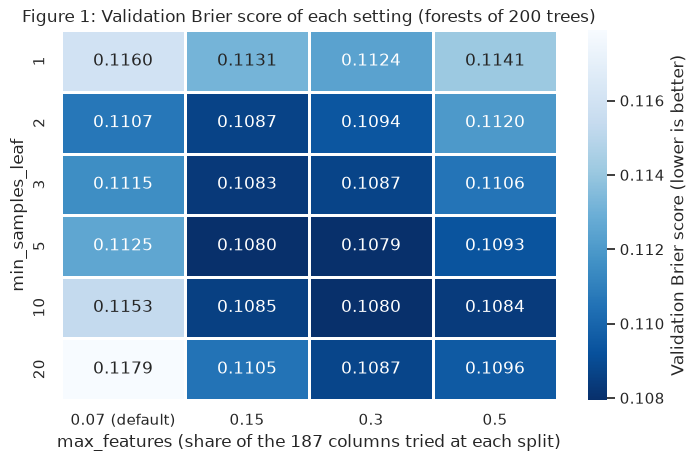

Best: max_features = 0.3, min_samples_leaf = 5 (validation Brier 0.1079)
Runner-up: max_features = 0.3, min_samples_leaf = 10, 0.00001 worse (paired standard error 0.00022)
Best on the validation bookings whose booking event is not in the training set: max_features = 0.3, min_samples_leaf = 5


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(results.pivot(index="min_samples_leaf", columns="max_features", values="val_brier"),
            annot=True, fmt=".4f", cmap="Blues_r", linewidths=2, linecolor="white",
            cbar_kws={"label": "Validation Brier score (lower is better)"}, ax=ax)
ax.set_xticklabels(["0.07 (default)", "0.15", "0.3", "0.5"])
ax.set_xlabel("max_features (share of the 187 columns tried at each split)")
ax.set_ylabel("min_samples_leaf")
ax.set_title("Figure 1: Validation Brier score of each setting (forests of 200 trees)")
plt.show()

best, runner_up = results.loc[0], results.loc[1]
best_unseen = results.loc[results.val_brier_event_unseen.idxmin()]
key = lambda row: (row.max_features, int(row.min_samples_leaf), None)
print(f"Best: max_features = {best.max_features}, min_samples_leaf = {best.min_samples_leaf:.0f} "
      f"(validation Brier {best.val_brier:.4f})")
print(f"Runner-up: max_features = {runner_up.max_features}, min_samples_leaf = {runner_up.min_samples_leaf:.0f}, "
      f"{runner_up.val_brier - best.val_brier:.5f} worse "
      f"(paired standard error {paired_se(val_preds[key(best)], val_preds[key(runner_up)]):.5f})")
print(f"Best on the validation bookings whose booking event is not in the training set: "
      f"max_features = {best_unseen.max_features}, min_samples_leaf = {best_unseen.min_samples_leaf:.0f}")

* **Fully grown trees do worst.** The top row of Figure 1, `min_samples_leaf` = 1 (scikit-learn's default), is the worst row for every `max_features` except the default 0.07, where very large leaves are even worse. Leaves of at least 2 to 10 bookings lower the Brier score by about 0.005. A leaf of one or two bookings makes each tree's prediction little more than a copy of one training outcome. Larger leaves average several outcomes, which lowers the variance $\sigma^2$ of each tree (Section 2.3) at little cost in bias. With 20 bookings per leaf the trees become too coarse and the score rises again.
* **The default `max_features` is too small.** The best shares are 0.15 and 0.3, that is 28 and 56 columns per split, two to four times the default of 13. Most of the 187 columns are one-hot columns for rare categories, so 13 randomly chosen columns often contain few useful splits, and the trees are too weak. At 0.5 the trees become more alike (a higher $\rho$), and the score is worse than at 0.3 for every leaf size.
* **The best region is flat.** The best setting, `max_features` = 0.3 with `min_samples_leaf` = 5, scores 0.1079. The runner-up is less than 0.0001 worse, with a paired standard error of 0.0002, and six settings lie within 0.0006 of the best. The exact choice within this region hardly matters.
* **The choice doesn't depend on booking events.** The same setting is best when we score only the 78.7% of validation bookings whose booking event does not occur in the training set. So the setting is not chosen for recognising rooms of one booking that fall on both sides of the split.

### 4.3 Bootstrap sample size and split criterion

Smaller bootstrap samples (`max_samples`) make the trees less alike, much as a smaller `max_features` does, and faster to grow. They also interact with the leaf size: a leaf of 5 bookings from a half-size sample covers roughly as much of the feature space as a leaf of 10 from a full-size one. We therefore try samples of 25% and 50% of the training set together with several leaf sizes, at the best `max_features`.

In [7]:
best_mf = float(best.max_features)
rows = []
for max_samples in [0.25, 0.5, None]:
    for min_samples_leaf in [2, 3, 5, 10]:
        if (best_mf, min_samples_leaf, max_samples) not in val_preds:
            forest = fit_forest(max_features=best_mf, min_samples_leaf=min_samples_leaf, max_samples=max_samples)
            val_preds[best_mf, min_samples_leaf, max_samples] = forest.predict_proba(X_val)[:, 1]
        p = val_preds[best_mf, min_samples_leaf, max_samples]
        rows.append({"bootstrap sample": f"{max_samples or 1:.0%} of training set", "max_samples": max_samples,
                     "min_samples_leaf": min_samples_leaf, "val_brier": brier_score_loss(y_val, p)})
stage2 = pd.DataFrame(rows)

best2 = stage2.loc[stage2.val_brier.idxmin()]
best_params = {"max_features": best_mf, "min_samples_leaf": int(best2.min_samples_leaf),
               "max_samples": None if pd.isna(best2.max_samples) else float(best2.max_samples)}
print("Best settings:", best_params)
(stage2.pivot(index="min_samples_leaf", columns="bootstrap sample", values="val_brier")
       [["25% of training set", "50% of training set", "100% of training set"]].round(4))

Best settings: {'max_features': 0.3, 'min_samples_leaf': 5, 'max_samples': 0.5}


bootstrap sample,25% of training set,50% of training set,100% of training set
min_samples_leaf,,,
2,0.1083,0.1089,0.1094
3,0.1080,0.1084,0.1087
5,0.1083,0.1073,0.1079
10,0.1093,0.1089,0.1080


Finally, we compare the Gini criterion with entropy at these settings.

In [8]:
p_gini = val_preds[best_params["max_features"], best_params["min_samples_leaf"], best_params["max_samples"]]
p_entropy = fit_forest(criterion="entropy", **best_params).predict_proba(X_val)[:, 1]
print(f"Difference in validation Brier (entropy - Gini): {brier_score_loss(y_val, p_entropy) - brier_score_loss(y_val, p_gini):+.4f} "
      f"(paired standard error {paired_se(p_entropy, p_gini):.4f})")
pd.DataFrame({"Gini": scores(p_gini), "Entropy": scores(p_entropy)}).T.round(4)

Difference in validation Brier (entropy - Gini): +0.0002 (paired standard error 0.0002)


,Brier,log-loss,AUC
Gini,0.1073,0.3408,0.9202
Entropy,0.1075,0.3401,0.9202


Half-size bootstrap samples with leaves of at least 5 bookings give the best validation score, 0.1073, against 0.1079 with full-size samples. The gain is small and not consistent across leaf sizes, and Section 4.4 shows that part of it is luck in the 200 trees that were grown. It costs nothing, though, and smaller samples make the forest faster to fit, so we use them. The table also shows the trade-off described above: the smaller the bootstrap sample, the smaller the best leaf (3 bookings with 25% samples, 5 with 50%, and 5 or 10 with full-size samples), because both settings control how many bookings each leaf averages over.

Splitting on entropy gives practically the same forest: the validation Brier score changes by 0.0002, about one standard error, the log loss by 0.0007, and the AUC not at all. This answers a worry raised in the metrics note (§1). Gini splitting greedily minimises the Brier score (Section 2.1), so the group's primary metric might seem to favour this forest. A forest grown to reduce log loss instead scores the same under both metrics, so the forest's results don't depend on which of the two it was grown to reduce. We keep the Gini criterion.

### 4.4 How many trees?

We fit the final forest with 1,000 trees. Because the forest's prediction is the average of its trees' predictions, we can work out the validation score of the forest made of its first $B$ trees for every $B$ from the trees' individual predictions. Figure 2 compares this curve with the formula of Section 2.3, $\mathrm{BS}_\infty + \bar\tau^2/B$, where $\bar\tau^2$ is the variance of the trees' predictions, averaged over the validation bookings, and $\mathrm{BS}_\infty$ is the estimated score of an infinitely large forest.

Final settings: {'n_estimators': 1000, 'max_features': 0.3, 'min_samples_leaf': 5, 'max_samples': 0.5}
Fitted 1,000 trees in 74 seconds


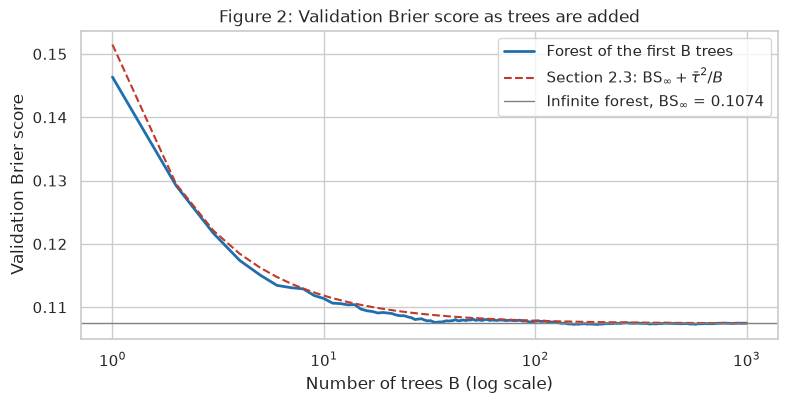

Average tree variance: 0.0440
Validation Brier score: B = 1: 0.1464, B = 10: 0.1114, B = 100: 0.1078, B = 200: 0.1073, B = 500: 0.1074, B = 1,000: 0.1075


In [9]:
N_TREES = 1000
final_params = {"n_estimators": N_TREES, **best_params}
start = time.time()
forest = fit_forest(**final_params)
print(f"Final settings: {final_params}")
print(f"Fitted {N_TREES:,} trees in {time.time() - start:.0f} seconds")

# Every tree's predictions for the validation set; the forest's prediction is their average
per_tree = np.stack([tree.predict_proba(X_val.to_numpy(dtype=np.float32))[:, 1] for tree in forest.estimators_])
p_val_raw = forest.predict_proba(X_val)[:, 1]
assert np.allclose(per_tree.mean(axis=0), p_val_raw)

n_trees = np.arange(1, N_TREES + 1)
brier_by_size = np.array([brier_score_loss(y_val, p) for p in per_tree.cumsum(axis=0) / n_trees[:, None]])
tau2 = per_tree.var(axis=0, ddof=1).mean()      # variance of one tree's prediction, averaged over bookings
brier_inf = brier_by_size[-1] - tau2 / N_TREES   # estimated score of an infinitely large forest
del per_tree

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(n_trees, brier_by_size, color=BLUE, lw=2, label="Forest of the first B trees")
ax.plot(n_trees, brier_inf + tau2 / n_trees, color=RED, lw=1.5, ls="--",
        label=r"Section 2.3: $\mathrm{BS}_\infty + \bar\tau^2/B$")
ax.axhline(brier_inf, color="grey", lw=1, label=rf"Infinite forest, $\mathrm{{BS}}_\infty$ = {brier_inf:.4f}")
ax.set_xscale("log")
ax.set_xlabel("Number of trees B (log scale)")
ax.set_ylabel("Validation Brier score")
ax.set_title("Figure 2: Validation Brier score as trees are added")
ax.legend()
plt.show()
print(f"Average tree variance: {tau2:.4f}")
print("Validation Brier score:", ", ".join(f"B = {b:,}: {brier_by_size[b - 1]:.4f}" for b in [1, 10, 100, 200, 500, 1000]))

The validation Brier score falls quickly over the first few dozen trees, from 0.146 for a single tree to 0.111 for 10 trees and 0.108 for 100, and then barely changes: 0.1075 with 1,000 trees, against an estimated 0.1074 for an infinitely large forest. The formula of Section 2.3 follows the curve closely, with an average tree variance of $\bar\tau^2 = 0.044$. It also justifies the 200 trees used for tuning, which add only $\bar\tau^2/200 \approx 0.0002$ to the expected score.

As Section 2.3 predicts, adding trees never makes the forest overfit, so no early stopping is needed. The formula describes the *average* over the forest's random choices, however, and a particular forest's curve wobbles around it once it has levelled off. The first 200 trees of this forest, which are the same 200 trees that won the search in Section 4.3 because the random seed is the same, score 0.1073, slightly better than all 1,000 together (0.1075): a single tree can be lucky or unlucky for many validation bookings at once. Differences of a few ten-thousandths between settings in Sections 4.2 and 4.3 are within this noise. We keep 1,000 trees; 500 would give almost the same score with half the memory.

## 5. Checking the model

### 5.1 Calibration

The hotel acts on the probabilities, not just on the ranking of bookings: the number of rooms to overbook depends on how many cancellations are expected. A model is **calibrated** if, among bookings given probability $p$, a proportion $p$ actually cancel. Figure 3 is a CORP reliability diagram (Dimitriadis, Gneiting & Jordan, 2021), drawn as in the group's scoring code: it plots the isotonic (PAV) regression of the outcome on the predicted probability, which needs no choice of bins. Below it is the distribution of the predictions. We also report the calibration intercept and slope of the Cox (1958) model $\operatorname{logit} P(Y = 1 \mid \hat p) = a + b \operatorname{logit}(\hat p)$, computed with `evaluate.py`. A calibrated model has intercept 0 and slope 1, a slope below 1 means over-confident probabilities, and a slope above 1 means timid ones (metrics note, §4).

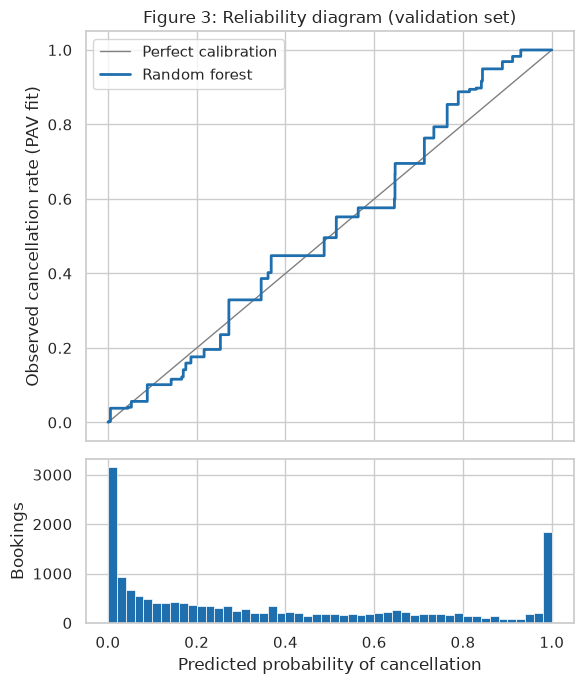

Calibration-in-the-large: 0.053 (target 0)   Calibration slope: 1.033 (target 1)
Mean predicted probability: 36.9%   Actual cancellation rate: 37.5%
Predicted exactly 1: 1,172 bookings, 100.0% cancelled, 100% non-refundable, market segments: Groups 75%, Offline TA/TO 25%
Predicted exactly 0: 246 bookings, 0.4% cancelled, 0% non-refundable, market segments: Offline TA/TO 78%, Groups 22%


In [10]:
y_v = y_val.to_numpy()
_, p_grid, p_pav = pav(p_val_raw, y_v)
fig, (ax, ax_hist) = plt.subplots(2, 1, figsize=(6, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax.plot([0, 1], [0, 1], color="grey", lw=1, label="Perfect calibration")
ax.step(p_grid, p_pav, where="post", color=BLUE, lw=2, label="Random forest")
ax.set_ylabel("Observed cancellation rate (PAV fit)")
ax.set_title("Figure 3: Reliability diagram (validation set)")
ax.legend(loc="upper left")
ax_hist.hist(p_val_raw, bins=np.linspace(0, 1, 51), color=BLUE, edgecolor="white", linewidth=0.5)
ax_hist.set_xlabel("Predicted probability of cancellation")
ax_hist.set_ylabel("Bookings")
plt.tight_layout()
plt.show()

citl, slope = calibration_intercept_slope(y_v, p_val_raw)
print(f"Calibration-in-the-large: {citl:.3f} (target 0)   Calibration slope: {slope:.3f} (target 1)")
print(f"Mean predicted probability: {p_val_raw.mean():.1%}   Actual cancellation rate: {y_v.mean():.1%}")
val_rows = df[is_val]
for value in [1, 0]:
    exact = p_val_raw == value
    segments = val_rows.market_segment[exact].value_counts(normalize=True).head(2)
    print(f"Predicted exactly {value}: {exact.sum():,} bookings, {y_v[exact].mean():.1%} cancelled, "
          f"{val_rows.deposit_type[exact].eq('Non Refund').mean():.0%} non-refundable, "
          f"market segments: {', '.join(f'{s} {share:.0%}' for s, share in segments.items())}")

The forest is already close to calibrated. The reliability curve stays near the diagonal, the calibration slope is 1.03 (very slightly timid), and the intercept of 0.05 reflects an average prediction of 36.9% against an actual cancellation rate of 37.5% in the validation set.

The histogram shows the problem that Section 2.5 described: 1,418 validation bookings (8%) are predicted with probability exactly 0 or exactly 1. All 1,172 predicted at exactly 1 were cancelled; they are all non-refundable, mostly group bookings. Of the 246 predicted at exactly 0, mostly tour-operator and group bookings, one was cancelled. Under log loss that one booking costs about 36 nats, and on its own adds 0.002 to the validation log loss. On the test set, a few such bookings could decide a log-loss comparison, which is why the protocol asks for recalibration.

Forests are often poorly calibrated, so why is this one well calibrated? The calibration slopes of the 24 forests in the grid search (Section 4.2) show that the two main hyperparameters control it:

In [11]:
results.pivot(index="min_samples_leaf", columns="max_features", values="calibration_slope").round(2)

max_features,0.07,0.15,0.30,0.50
min_samples_leaf,,,,
1,0.62,0.55,0.49,0.45
2,1.33,1.01,0.85,0.71
3,1.43,1.08,0.89,0.79
5,1.53,1.15,0.96,0.87
10,1.66,1.24,1.05,0.95
20,1.76,1.32,1.11,1.01


The slope moves steadily with both hyperparameters. Forests of fully grown trees are strongly over-confident (slopes 0.45 to 0.62): pure leaves of one or two bookings make every tree certain, and when the trees agree the forest is certain too. Larger leaves make each tree's prediction an average over several bookings, and the forest becomes timid (slopes above 1), the behaviour Niculescu-Mizil and Caruana (2005) describe for forests in general. A larger `max_features` pushes the other way, because trees that are more alike agree more often. The three best settings of Section 4.2 lie where the two effects balance, with slopes of 0.96, 1.05 and 1.15. This is what tuning on the Brier score should do: it penalises miscalibration as well as poor ranking (the MCB term in §3.2 of the metrics note), so it chose settings that are calibrated as well as sharp.

### 5.2 Recalibration

We compare two ways of recalibrating the forest on the validation set (metrics note, §4):

* **Logistic recalibration** (Platt scaling in the form of the Cox model): fit $\operatorname{logit} P(Y = 1) = a + b \operatorname{logit}(\hat p)$ by maximum likelihood (Platt, 1999; Cox, 1958). Before taking logits we clip the predictions to $[\varepsilon, 1 - \varepsilon]$ with $\varepsilon = 1/(2B) = 0.0005$, half of one tree's vote, so that predictions of exactly 0 or 1 have finite logits. The fitted map never returns exactly 0 or 1.
* **Isotonic regression**, the best non-decreasing map from $\hat p$ to the outcome (Zadrozny & Elkan, 2002). It is more flexible, but it can return exactly 0 or 1.

A map fitted to the validation set and scored on the same bookings would look too good. We therefore **cross-fit**: we split the validation set into five folds that keep identical rows together (as §7.2 of the metrics note requires), fit each map on four folds, and predict the fifth.

In [12]:
EPS = 0.5 / N_TREES   # half of one tree's vote

def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))

class LogisticRecalibration:
    # Platt scaling in the form of the Cox model: logit P(cancel) = a + b logit(p)
    def fit(self, p, y_true):
        self.model = LogisticRegression(C=np.inf).fit(logit(p).reshape(-1, 1), y_true)
        self.a, self.b = self.model.intercept_[0], self.model.coef_[0, 0]
        return self

    def predict(self, p):
        return self.model.predict_proba(logit(p).reshape(-1, 1))[:, 1]

recalibrators = {"Logistic (Platt / Cox)": LogisticRecalibration,
                 "Isotonic regression": lambda: IsotonicRegression(out_of_bounds="clip")}
folds = list(GroupKFold(n_splits=5).split(p_val_raw, y_v, groups=block[is_val]))

recal_results = {"None (raw forest)": {**scores(p_val_raw), "exactly 0 or 1": np.isin(p_val_raw, [0, 1]).sum()}}
cross_fitted = {}
for name, make in recalibrators.items():
    p_cf = np.empty_like(p_val_raw)
    for fit_rows, score_rows in folds:
        p_cf[score_rows] = make().fit(p_val_raw[fit_rows], y_v[fit_rows]).predict(p_val_raw[score_rows])
    cross_fitted[name] = p_cf
    recal_results[name] = {**scores(p_cf), "exactly 0 or 1": np.isin(p_cf, [0, 1]).sum()}
recal_results = pd.DataFrame(recal_results).T.astype({"exactly 0 or 1": int})
recal_results.round(4)

,Brier,log-loss,AUC,exactly 0 or 1
None (raw forest),0.1075,0.3409,0.9200,1418
Logistic (Platt / Cox),0.1076,0.3411,0.9195,0
Isotonic regression,0.1079,0.3475,0.9174,2568


Logistic recalibration is the better choice. It leaves the cross-fitted scores almost unchanged (Brier score 0.1076 against 0.1075 for the raw forest; the AUC moves slightly only because each fold gets its own map) and removes every prediction of exactly 0 or 1. Isotonic regression does worse on all three scores and produces *more* predictions of exactly 0 or 1 (2,568), because its fitted steps at the two ends are often pure. Recalibration can't improve a forest that is already this well calibrated; its job here is to make the probabilities safe to score with log loss. We fit the logistic map to the whole validation set for the final model.

In [13]:
recalibration = LogisticRecalibration().fit(p_val_raw, y_v)
print(f"Fitted on the whole validation set: a = {recalibration.a:.3f}, b = {recalibration.b:.3f}")
examples = np.array([0, 0.01, 0.1, 0.5, 0.9, 0.99, 1])
pd.DataFrame({"Raw forest": examples, "Recalibrated": recalibration.predict(examples)}).set_index("Raw forest").T.round(4)

Fitted on the whole validation set: a = 0.070, b = 1.037


Raw forest,0.00,0.01,0.10,0.50,0.90,0.99,1.00
Recalibrated,0.0004,0.0091,0.099,0.5175,0.9129,0.9921,0.9996


The fitted map changes the forest's probabilities very little. It raises predictions above about 0.2 by up to 2 percentage points, which brings the average prediction up to the validation set's cancellation rate, and it moves predictions of exactly 0 and 1 to 0.0004 and 0.9996.

### 5.3 Which features does the forest use?

A forest spreads each feature's effect over a thousand trees, so we summarise it in two ways:

* **Impurity importance** (mean decrease in impurity): the total fall in Gini impurity from all splits on a feature, averaged over the trees. It is free to compute, but it is measured on the training data and is biased towards continuous features and features with many categories, which offer many possible split points (Strobl et al., 2007).
* **Permutation importance** (Breiman, 2001): how much the validation Brier score rises when a feature's values are shuffled across bookings, which breaks its link with the outcome. We shuffle the one-hot columns of a categorical feature together, and repeat each shuffle three times.

Both add up the contributions of a feature's one-hot columns, and both show what the model *uses*, not what causes cancellations. Permutation importance is also unreliable for strongly correlated features: shuffling one of them creates bookings unlike any in the data, such as a stay whose total length doesn't match its weekday and weekend nights (Hooker, Mentch & Zhou, 2021).

Permutation importance computed in 70 seconds


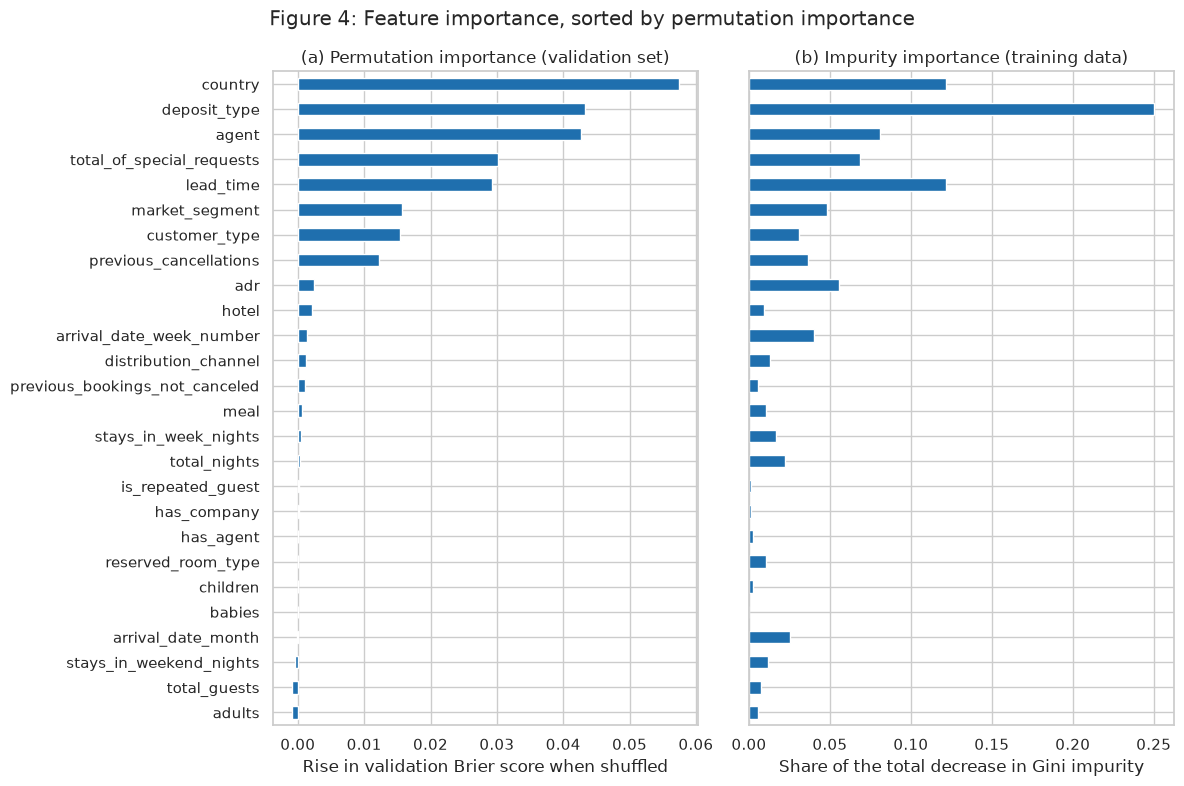

Permutation: country 0.0574, deposit_type 0.0432, agent 0.0426, total_of_special_requests 0.0301, lead_time 0.0293, market_segment 0.0158, customer_type 0.0154, previous_cancellations 0.0123, adr 0.0024, hotel 0.0021, arrival_date_week_number 0.0014
Impurity:    deposit_type 0.250, lead_time 0.122, country 0.122, agent 0.081, total_of_special_requests 0.069, adr 0.056, market_segment 0.048, arrival_date_week_number 0.040, previous_cancellations 0.037, customer_type 0.031, arrival_date_month 0.026


In [14]:
rng = np.random.default_rng(RANDOM_STATE)
base = brier_score_loss(y_val, p_val_raw)
permutation = {}
start = time.time()
for feature in original.unique():
    cols = np.flatnonzero(original == feature)
    rises = []
    for _ in range(3):
        X_shuffled = X_val.copy()
        X_shuffled.iloc[:, cols] = X_val.iloc[rng.permutation(len(X_val)), cols].to_numpy()
        rises.append(brier_score_loss(y_val, forest.predict_proba(X_shuffled)[:, 1]) - base)
    permutation[feature] = np.mean(rises)
print(f"Permutation importance computed in {time.time() - start:.0f} seconds")

permutation = pd.Series(permutation).sort_values()
impurity = pd.Series(forest.feature_importances_, index=X.columns).groupby(original).sum().reindex(permutation.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
permutation.plot(kind="barh", color=BLUE, ax=ax1)
ax1.set_xlabel("Rise in validation Brier score when shuffled")
ax1.set_title("(a) Permutation importance (validation set)")
impurity.plot(kind="barh", color=BLUE, ax=ax2)
ax2.set_xlabel("Share of the total decrease in Gini impurity")
ax2.set_title("(b) Impurity importance (training data)")
fig.suptitle("Figure 4: Feature importance, sorted by permutation importance")
plt.tight_layout()
plt.show()
print("Permutation:", ", ".join(f"{f} {v:.4f}" for f, v in permutation.sort_values(ascending=False).head(11).items()))
print("Impurity:   ", ", ".join(f"{f} {v:.3f}" for f, v in impurity.sort_values(ascending=False).head(11).items()))

Both measures agree on the five most important features: **country**, **deposit type**, **agent**, **special requests** and **lead time**, followed by market segment, customer type and previous cancellations. Shuffling the country alone raises the validation Brier score by 0.057, about half its value. The other 18 features matter little: shuffling any one of them raises the Brier score by less than 0.003, and for a few, such as the number of adults, shuffling slightly *lowers* it, so the forest gains nothing from them on new bookings.

The two measures disagree in the way Strobl et al. (2007) describe. Impurity importance ranks lead time level with country, and gives the price (`adr`) 6% of the total and the arrival week 4%, yet shuffling these two raises the validation Brier score by only 0.0024 and 0.0014. Features with many possible split points are split on often, deep in the trees, where the splits mostly fit noise in the training data, and impurity importance counts those splits as if they were useful. Impurity importance also gives deposit type a quarter of the total, because the split on non-refundable deposits sits near the top of almost every tree and removes a lot of impurity from the training data.

The arrival month and week number, which the protocol keeps as features, matter little to the forest. Two cautions apply. Features that carry the same information share the credit, so the stay lengths and guest counts each look unimportant partly because `total_nights` and `total_guests` duplicate them (Hooker, Mentch & Zhou, 2021). And the importances show what the model uses, not what causes cancellations.

## 6. Final model and test-set predictions

The final model is the forest of Section 4.4 (1,000 trees, fitted on the training set), followed by the logistic recalibration of Section 5.2, fitted on the whole validation set. The table summarises its validation performance with the metrics of the group's protocol. The skill score is measured against always predicting the training cancellation rate. The recalibrated column uses the cross-fitted predictions, so that the recalibration is not scored on the bookings it was fitted to. Both columns are still somewhat optimistic, because the same validation set was used to choose the settings (metrics note, §7.2); the test set will give the unbiased estimate.

In [15]:
reference_rate = y_train.mean()

def summary(p):
    citl, slope = calibration_intercept_slope(y_v, p)
    brier = brier_score_loss(y_v, p)
    return {"Brier score": brier, "Brier skill score": 1 - brier / brier_score_loss(y_v, np.full(len(p), reference_rate)),
            "Log-loss": log_loss(y_v, p), "ROC AUC": roc_auc_score(y_v, p),
            "Calibration-in-the-large": citl, "Calibration slope": slope,
            "Predictions exactly 0 or 1": np.isin(p, [0, 1]).sum()}

summary_table = pd.DataFrame({"Raw forest": summary(p_val_raw),
                              "Recalibrated (cross-fitted)": summary(cross_fitted["Logistic (Platt / Cox)"])}).T
summary_table.astype({"Predictions exactly 0 or 1": int}).round(4)

,Brier score,Brier skill score,Log-loss,ROC AUC,Calibration-in-the-large,Calibration slope,Predictions exactly 0 or 1
Raw forest,0.1075,0.5415,0.3409,0.9200,0.0529,1.0334,1418
Recalibrated (cross-fitted),0.1076,0.5411,0.3411,0.9195,-0.0005,0.9869,0


**Saving the test predictions.** Following the protocol (§10.5 and §11), we save the recalibrated probability of cancellation for every test booking as `LukeD/test_preds.csv`, with columns `id,prediction`, where `id` is the booking's 0-based row number in `hotel_bookings_clean.csv`. The test labels are not used here: the file will be scored with `evaluate.py` once all three models are finished.

In [16]:
p_test = recalibration.predict(forest.predict_proba(X_test)[:, 1])
test_preds = pd.DataFrame({"id": df.index[is_test], "prediction": p_test})
assert len(test_preds) == 17_903 and test_preds.prediction.between(0, 1, inclusive="neither").all()
test_preds.to_csv("../LukeD/test_preds.csv", index=False)
print(f"Saved test_preds.csv: {len(test_preds):,} test bookings, predictions from {p_test.min():.4f} to {p_test.max():.4f}")

Saved test_preds.csv: 17,903 test bookings, predictions from 0.0004 to 0.9996


## 7. Summary

* **Model.** A random forest averages many deep classification trees, each grown on a bootstrap sample of the bookings and choosing each split from a random subset of the columns. Each Gini tree greedily minimises its training Brier score, averaging reduces the trees' variance, and, for the Brier score, adding trees can only help on average.
* **Validation.** We tuned on the shared validation set. The forest's built-in out-of-bag estimate can't be trusted on our data: for bookings with identical copies it gives a Brier score of 0.009, against 0.103 on the validation set.
* **Tuning.** Leaves of at least 5 bookings, 30% of the columns at each split and half-size bootstrap samples work best. scikit-learn's defaults (fully grown trees, 13 columns per split) give a validation Brier score of 0.1160, against 0.1075 for the tuned forest of 1,000 trees. The best settings form a flat region, and splitting on entropy instead of Gini makes no difference.
* **Calibration.** The tuned forest is close to calibrated (calibration slope 1.03), but 8% of its validation predictions are exactly 0 or 1, and one booking predicted at exactly 0 was cancelled. Logistic recalibration, fitted on the validation set, removes them at no measurable cost.
* **Validation results** (recalibrated, cross-fitted): Brier score 0.1076, a skill score of 0.54 against always predicting the training cancellation rate, log loss 0.3411, AUC 0.9195 and calibration slope 0.99. These are slightly optimistic, because the validation set was also used to choose the settings.
* **Features.** The forest relies most on country, deposit type, agent, special requests and lead time. The arrival month and week number contribute little.
* **Test predictions** for the 17,903 test bookings are saved in `LukeD/test_preds.csv`, ready to be scored with `evaluate.py` once all three models are finished.
* **Main limitation.** As for any model on our random split, the validation bookings come from the same months and years as the training bookings, and 21% of them share a booking event with a training booking. The protocol's chronological check (§10.9) will show how well the forest predicts *future* bookings; the final settings are stored in `final_params` for that refit.

## References

* Breiman, L. (1996a). [Bagging predictors](https://doi.org/10.1007/BF00058655). *Machine Learning*, 24(2), 123–140.
* Breiman, L. (1996b). *Out-of-bag estimation*. Technical report, Department of Statistics, University of California, Berkeley.
* Breiman, L. (2001). [Random forests](https://doi.org/10.1023/A:1010933404324). *Machine Learning*, 45(1), 5–32.
* Breiman, L., Friedman, J. H., Olshen, R. A. and Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
* Cox, D. R. (1958). [Two further applications of a model for binary regression](https://doi.org/10.1093/biomet/45.3-4.562). *Biometrika*, 45(3/4), 562–565.
* Dimitriadis, T., Gneiting, T. and Jordan, A. I. (2021). [Stable reliability diagrams for probabilistic classifiers](https://doi.org/10.1073/pnas.2016191118). *Proceedings of the National Academy of Sciences*, 118(8), e2016191118.
* Hastie, T., Tibshirani, R. and Friedman, J. (2009). [*The Elements of Statistical Learning*](https://hastie.su.domains/ElemStatLearn/), 2nd edition, Chapter 15. Springer.
* Hooker, G., Mentch, L. and Zhou, S. (2021). [Unrestricted permutation forces extrapolation: variable importance requires at least one more model, or there is no free variable importance](https://doi.org/10.1007/s11222-021-10057-z). *Statistics and Computing*, 31, 82.
* Niculescu-Mizil, A. and Caruana, R. (2005). [Predicting good probabilities with supervised learning](https://doi.org/10.1145/1102351.1102430). *Proceedings of ICML*, 625–632.
* Pedregosa, F. et al. (2011). [Scikit-learn: machine learning in Python](https://www.jmlr.org/papers/v12/pedregosa11a.html). *Journal of Machine Learning Research*, 12, 2825–2830.
* Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In *Advances in Large Margin Classifiers*, 61–74. MIT Press.
* Probst, P. and Boulesteix, A.-L. (2018). To tune or not to tune the number of trees in random forest. *Journal of Machine Learning Research*, 18(181), 1–18.
* Probst, P., Wright, M. N. and Boulesteix, A.-L. (2019). [Hyperparameters and tuning strategies for random forest](https://doi.org/10.1002/widm.1301). *WIREs Data Mining and Knowledge Discovery*, 9(3), e1301.
* Strobl, C., Boulesteix, A.-L., Zeileis, A. and Hothorn, T. (2007). [Bias in random forest variable importance measures: illustrations, sources and a solution](https://doi.org/10.1186/1471-2105-8-25). *BMC Bioinformatics*, 8, 25.
* Zadrozny, B. and Elkan, C. (2002). [Transforming classifier scores into accurate multiclass probability estimates](https://doi.org/10.1145/775047.775151). *Proceedings of KDD*, 694–699.